# Walkthrough: German daily gas demand, 1-14 days ahead

This notebook is a readable tour of the project. **All logic lives in `src/`**; the notebook
only imports it, re-runs a few small steps live and reads the tables that
`python -m src.pipeline` wrote to `reports/tables/`. Run `python data/download_data.py` first.

Contents
1. Data and the heating-demand relationship
2. SARIMAX specification chosen on validation folds (residual autocorrelation fix)
3. One leakage-safe forecast, live
4. Calibrated (conformal) prediction intervals, recomputed from the stored backtest
5. Forecast combination and Diebold-Mariano tests
6. Regime robustness: 2021 vs 2022
7. Day-ahead view

In [1]:
import json
import os
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
from IPython.display import Image, display

from src import config
from src.backtest import rolling_origin_splits
from src.config import BacktestConfig, TempForecastConfig
from src.conformal import gaussian_quantiles, rolling_conformal
from src.data import build_dataset
from src.evaluation import dm_table, probabilistic_scores
from src.features import temperature_forecast_archive
from src.metrics import coverage, mae, mape
from src.models import SarimaxForecaster
from src.sarimax_selection import candidate_specs

pd.set_option("display.precision", 3)
pd.set_option("display.width", 140)
T = config.TABLE_DIR
summary = json.loads((T / "run_summary.json").read_text())
summary

{'n_days': 2283,
 'start': '2016-10-01',
 'end': '2022-12-31',
 'n_validation_origins': 22,
 'first_validation_origin': '2019-09-29',
 'n_test_origins': 34,
 'first_test_origin': '2021-01-03',
 'last_test_origin': '2022-11-27',
 'arima_order': [1, 1, 2],
 'sarimax_spec': '+ non-linear HDD + weekly AR',
 'best_combination': 'Combination (inv_mse)',
 'n_day_ahead_test_days': 727,
 'runtime_seconds': 589.5}

## 1. Data

National demand = NCG + GASPOOL until 2021-09-30, then THE; ERA5 country-average temperature.

In [2]:
df = build_dataset()
print(f"{len(df)} days, {df.index[0].date()} .. {df.index[-1].date()}, "
      f"mean {df['total'].mean():.0f} GWh/day")
df.describe().T[["mean", "std", "min", "max"]]

2283 days, 2016-10-01 .. 2022-12-31, mean 2663 GWh/day


,mean,std,min,max
slp,1091.991,760.738,146.915,3353.489
rlm,1571.421,382.734,731.597,2788.909
total,2663.412,1107.494,906.193,6125.445
temp,10.019,7.079,-9.725,27.636
hdd,6.069,5.669,0.000,24.725


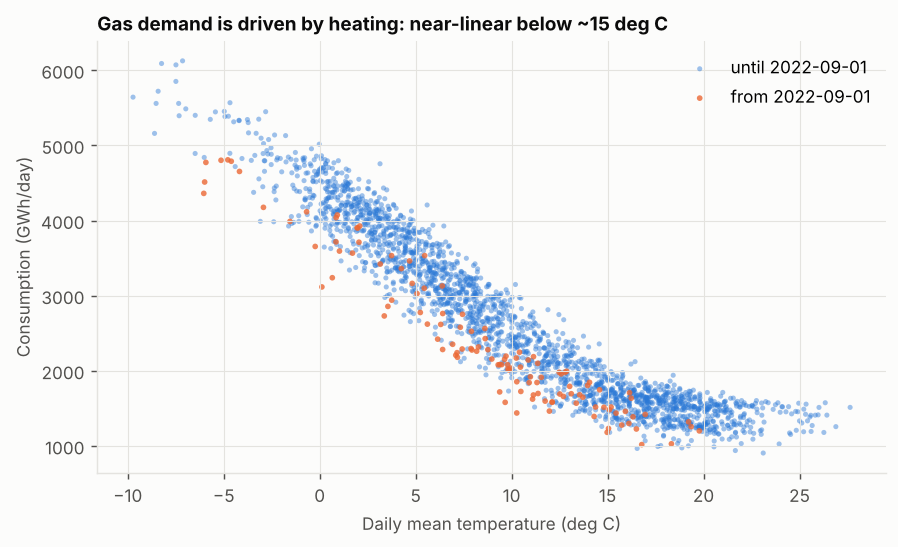

In [3]:
display(Image(str(config.FIG_DIR / "fig2_demand_vs_temperature.png"), width=620))

## 2. SARIMAX specification, chosen on validation folds only

The baseline (ARIMA(1,1,2) errors on weighted HDD + calendar) left residual
autocorrelation. Four candidates were run on 22 validation origins (2019-09-29 .. 2020-12-13,
all targets before the first test origin). Rule fixed in advance: lowest pooled MAE.
Ljung-Box p-values are computed on the fit to all pre-test data.

In [4]:
sel = pd.read_csv(T / "sarimax_spec_validation.csv", index_col=0)
sel

,valid_MAE,valid_RMSE,valid_MAPE,valid_coverage,BIC_pretest,LB_p_lag7,LB_p_lag14,LB_p_lag28
spec,,,,,,,,
baseline,181.154,240.203,6.598,0.692,18118.831,0.004,0.040,0.051
+ weekly AR,180.749,240.284,6.577,0.688,18120.058,0.014,0.182,0.229
+ non-linear HDD,176.814,238.046,6.354,0.688,18011.459,0.016,0.214,0.564
+ non-linear HDD + weekly AR,176.521,237.820,6.341,0.688,18017.517,0.012,0.225,0.610


In [5]:
print(f"chosen specification: {summary['sarimax_spec']}")
print((T / "sarimax_chosen_fit.txt").read_text()[:3200])

chosen specification: + non-linear HDD + weekly AR
                                     SARIMAX Results                                      
Dep. Variable:                              total   No. Observations:                 1553
Model:             SARIMAX(1, 1, 2)x(1, 0, [], 7)   Log Likelihood               -8949.980
Date:                            Sat, 14 Nov 2026   AIC                          17931.961
Time:                                    19:36:50   BIC                          18017.517
Sample:                                10-04-2016   HQIC                         17963.779
                                     - 01-03-2021                                         
Covariance Type:                              opg                                         
                    coef    std err          z      P>|z|      [0.025      0.975]
---------------------------------------------------------------------------------
hdd_w           147.3819      2.506     58.810      0.000

## 3. One forecast, live

Refit the chosen specification at the last test origin. The future temperature is the
*simulated forecast* issued at the origin, never the realised value.

In [6]:
cfg = BacktestConfig()
archive = temperature_forecast_archive(df["temp"], cfg.horizon, TempForecastConfig(), config.SEED)
folds = list(rolling_origin_splits(df.index, cfg.first_origin, cfg.step_days, cfg.horizon))
spec = next(s for s in candidate_specs(tuple(summary["arima_order"]))
            if s.name == summary["sarimax_spec"])
fc = SarimaxForecaster(df["total"], df["temp"], archive, spec)
last = folds[-1]
live = fc(last).assign(actual=df["total"].loc[last.test_index])
live["inside_raw_90"] = live["actual"].between(live["lo"], live["hi"])
print(f"origin {last.origin.date()}, MAE {mae(live.actual, live['mean']):.0f} GWh/day")
live.round(0)

origin 2022-11-27, MAE 237 GWh/day


,mean,lo,hi,actual,inside_raw_90
date,,,,,
2022-11-28,3177.0,3046.0,3307.0,3361.0,False
2022-11-29,3128.0,2951.0,3306.0,3462.0,False
2022-11-30,3177.0,2983.0,3372.0,3533.0,False
2022-12-01,3241.0,3036.0,3446.0,3712.0,False
2022-12-02,3608.0,3395.0,3821.0,3716.0,True
2022-12-03,3466.0,3247.0,3686.0,3655.0,True
2022-12-04,3901.0,3674.0,4127.0,3594.0,False
2022-12-05,3854.0,3620.0,4088.0,3927.0,True
2022-12-06,3708.0,3466.0,3949.0,3901.0,True


## 4. Calibrated intervals (rolling split conformal)

At each test origin the calibration set contains the same model's past backtest errors
whose **target date is on or before the origin** (validation folds first, then earlier test
folds). The primary variant scales errors by the model's own predictive sd and pools all
horizons; the per-horizon variant uses raw signed errors of the same horizon. This cell
recomputes the SARIMAX numbers from the stored forecasts.

In [7]:
bt_all = pd.read_csv(T / "backtest_forecasts.csv", parse_dates=["origin", "date"])
test_origins = pd.DatetimeIndex([f.origin for f in folds])
s_all = bt_all[bt_all["model"] == "SARIMAX"]
raw = gaussian_quantiles(s_all[s_all["origin"].isin(test_origins)], cfg.interval_level)
cal = rolling_conformal(s_all, test_origins, cfg.interval_level, "scaled")
pd.DataFrame({"raw": probabilistic_scores(raw, cfg.interval_level),
              "conformal (scaled)": probabilistic_scores(cal, cfg.interval_level)}).T

,coverage,below_lo,above_hi,width,interval_score,pinball_0.05,pinball_0.95,CRPS_q19,n
raw,0.763,0.124,0.113,447.454,1045.497,25.611,26.664,118.369,476.0
conformal (scaled),0.916,0.061,0.023,787.137,902.702,21.445,23.690,119.290,476.0


In [8]:
pd.read_csv(T / "interval_calibration.csv", index_col=[0, 1])

coverage  below_lo  above_hi     width  interval_score  pinball_0.05  pinball_0.95  CRPS_q19  \
model                 method                                                                                                              
SARIMAX               raw                     0.763     0.124     0.113   447.454        1045.497        25.611        26.664   118.369   
                      conformal (horizon)     0.945     0.042     0.013   874.961         957.026        21.284        26.567   121.815   
                      conformal (scaled)      0.916     0.061     0.023   787.137         902.702        21.445        23.690   119.290   
SARIMAX baseline      raw                     0.758     0.124     0.118   459.595        1112.584        27.297        28.332   124.827   
                      conformal (horizon)     0.935     0.048     0.017   893.091         996.575        22.706        27.123   127.789   
                      conformal (scaled)      0.908     0.067     0.025   784.679         953.940        23.352        24.345   125.460   
LightGBM              raw                     0.712     0.176     0.111   576.931        1391.076        39.786        29.768   155.897   
                      conformal (horizon)     0.901     0.074     0.025  1133.379        1636.447        50.680        31.142   171.077   
                      conformal (scaled)      0.815     0.155     0.029   784.930        1216.475        33.065        27.759   162.359   
Combination (equal)   raw                     0.786     0.113     0.101   512.193         872.383        21.016        22.603   119.221   
                      conformal (horizon)     0.920     0.067     0.013   889.471        1114.854        28.395        27.348   129.126   
                      conformal (scaled)      0.857     0.124     0.019   648.121         907.306        22.723        22.642   124.378   
Combination (inv_mse) raw                     0.800     0.111     0.088   500.977         883.582        21.484        22.696   117.997   
                      conformal (horizon)     0.920     0.067     0.013   884.158        1096.992        27.654        27.196   127.491   
                      conformal (scaled)      0.859     0.122     0.019   637.743         902.450        22.829        22.294   123.045   

                                               n  
model                 method                      
SARIMAX               raw                  476.0  
                      conformal (horizon)  476.0  
                      conformal (scaled)   476.0  
SARIMAX baseline      raw                  476.0  
                      conformal (horizon)  476.0  
                      conformal (scaled)   476.0  
LightGBM              raw                  476.0  
                      conformal (horizon)  476.0  
                      conformal (scaled)   476.0  
Combination (equal)   raw                  476.0  
                      conformal (horizon)  476.0  
                      conformal (scaled)   476.0  
Combination (inv_mse) raw                  476.0  
                      conformal (horizon)  476.0  
                      conformal (scaled)   476.0

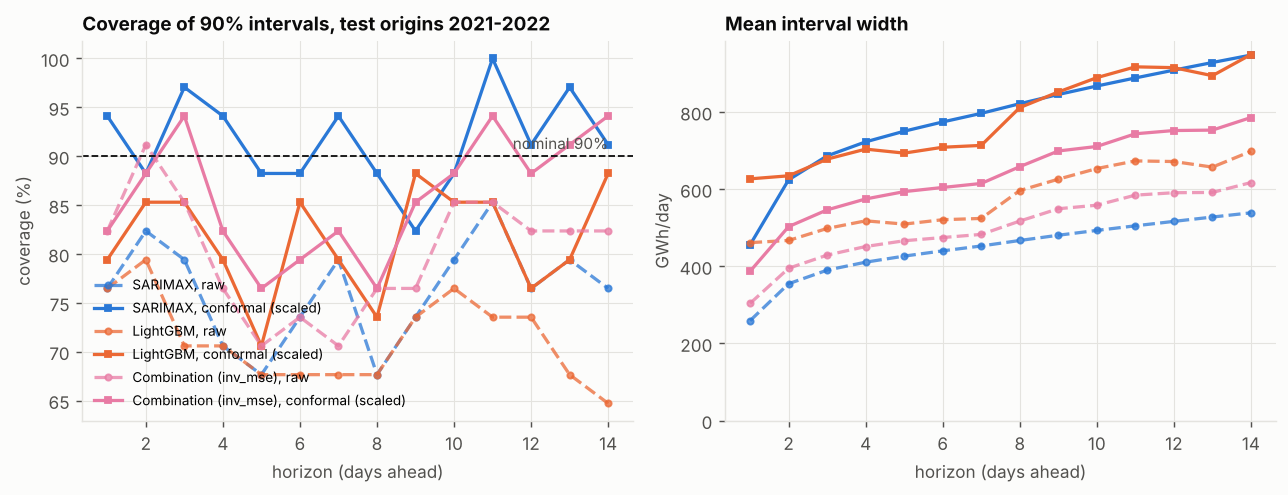

In [9]:
display(Image(str(config.FIG_DIR / "fig7_interval_calibration.png"), width=820))

## 5. Combination and Diebold-Mariano

Negative DM statistic = first model has the lower loss.

In [10]:
bt = bt_all[bt_all["origin"].isin(test_origins)]
pd.read_csv(T / "metrics_overall.csv", index_col=0)[["MAE", "RMSE", "MAPE", "MASE", "coverage", "n"]]

,MAE,RMSE,MAPE,MASE,coverage,n
model,,,,,,
SARIMAX,154.099,203.137,6.572,0.384,0.763,476.0
Combination (inv_mse),156.376,210.672,6.636,0.390,0.800,476.0
Combination (equal),158.477,212.130,6.735,0.395,0.786,476.0
SARIMAX baseline,161.121,213.564,6.837,0.402,0.758,476.0
LightGBM,206.920,283.757,8.621,0.516,0.712,476.0
ETS,394.414,609.602,15.584,0.982,0.929,476.0
Seasonal naive,482.626,669.153,18.304,1.200,0.910,476.0


In [11]:
pd.concat([dm_table(bt, "Combination (equal)", "SARIMAX"),
           dm_table(bt, "Combination (inv_mse)", "SARIMAX")])

DM_stat  p_value   n
comparison                       horizon     loss                          
Combination (equal) vs SARIMAX   1           squared     1.590    0.121  34
                                             absolute    1.913    0.064  34
                                 3           squared     0.110    0.913  34
                                             absolute   -0.173    0.864  34
                                 7           squared     0.806    0.426  34
                                             absolute    1.126    0.268  34
                                 14          squared     0.028    0.978  34
                                             absolute   -0.468    0.643  34
                                 1-14 pooled squared     0.597    0.555  34
                                             absolute    0.390    0.699  34
Combination (inv_mse) vs SARIMAX 1           squared     0.501    0.620  34
                                             absolute    0.836    0.409  34
                                 3           squared    -0.219    0.828  34
                                             absolute   -0.224    0.824  34
                                 7           squared     0.793    0.433  34
                                             absolute    1.161    0.254  34
                                 14          squared     0.151    0.881  34
                                             absolute   -0.393    0.697  34
                                 1-14 pooled squared     0.525    0.603  34
                                             absolute    0.221    0.827  34

In [12]:
pd.read_csv(T / "combination_weights_by_h.csv", index_col=0).T

h,1,2,3,4,5,6,7,8,9,10,11,12,13,14
SARIMAX,0.784,0.643,0.64,0.618,0.556,0.619,0.596,0.608,0.548,0.608,0.565,0.533,0.539,0.53
LightGBM,0.216,0.357,0.36,0.382,0.444,0.381,0.404,0.392,0.452,0.392,0.435,0.467,0.461,0.47


## 6. Regime robustness: pre-crisis 2021 vs crisis 2022

In [13]:
reg = pd.read_csv(T / "metrics_by_regime.csv", index_col=[0, 1])
reg[["MAE", "MAPE", "bias", "coverage_raw", "coverage_conformal", "n"]]

MAE    MAPE     bias  coverage_raw  coverage_conformal    n
regime                            model                                                                                 
2021 pre-crisis                   SARIMAX baseline       163.556   6.197   10.096         0.745               0.897  243
                                  SARIMAX                157.464   6.000   11.013         0.724               0.905  243
                                  LightGBM               226.747   8.049   22.560         0.724               0.848  243
                                  Seasonal naive         564.400  19.872  -94.802         0.881                 NaN  243
                                  ETS                    450.059  16.150  -96.942         0.905                 NaN  243
                                  Combination (equal)    170.479   6.237   16.787         0.778               0.860  243
                                  Combination (inv_mse)  169.061   6.212   12.786         0.782               0.852  243
2022 crisis                       SARIMAX baseline       158.581   7.504  -12.485         0.773               0.918  233
                                  SARIMAX                150.589   7.167  -16.727         0.803               0.927  233
                                  LightGBM               186.241   9.218 -108.749         0.700               0.781  233
                                  Seasonal naive         397.342  16.669  -20.971         0.940                 NaN  233
                                  ETS                    336.381  14.994  -57.823         0.953                 NaN  233
                                  Combination (equal)    145.959   7.254  -62.738         0.794               0.854  233
                                  Combination (inv_mse)  143.148   7.079  -52.921         0.820               0.867  233
  2022 Jan-Aug                    SARIMAX baseline       142.400   6.788  -26.264         0.810               0.933  163
                                  SARIMAX                142.271   6.785  -32.257         0.810               0.926  163
                                  LightGBM               146.033   7.263  -50.495         0.687               0.791  163
                                  Seasonal naive         396.879  17.326 -178.337         0.951                 NaN  163
                                  ETS                    344.044  15.863 -178.850         0.945                 NaN  163
                                  Combination (equal)    137.752   6.755  -41.376         0.816               0.871  163
                                  Combination (inv_mse)  137.665   6.723  -39.328         0.834               0.883  163
  2022 Sep-Dec (demand reduction) SARIMAX baseline       196.260   9.170   19.603         0.686               0.886   70
                                  SARIMAX                169.958   8.059   19.436         0.786               0.929   70
                                  LightGBM               279.869  13.771 -244.395         0.729               0.757   70
                                  Seasonal naive         398.421  15.140  345.466         0.914                 NaN   70
                                  ETS                    318.537  12.970  223.996         0.971                 NaN   70
                                  Combination (equal)    165.069   8.416 -112.480         0.743               0.814   70
                                  Combination (inv_mse)  155.914   7.908  -84.574         0.786               0.829   70

## 7. Day-ahead (h = 1 every day of the test period)

In [14]:
pd.read_csv(T / "day_ahead_metrics.csv", index_col=0)

,MAE,RMSE,MAPE,bias,n,coverage_90_raw,width_raw,coverage_90_conformal,width_conformal
model,,,,,,,,,
SARIMAX,73.277,99.172,3.062,-8.990,727.0,0.831,259.217,0.93,371.713
SARIMAX baseline,76.660,102.321,3.257,-8.761,727.0,0.836,270.285,NaN,NaN
Combination (inv_mse),79.571,105.829,3.234,-18.309,727.0,NaN,NaN,NaN,NaN
Combination (equal),101.398,137.154,4.007,-30.153,727.0,NaN,NaN,NaN,NaN
LightGBM,164.381,229.576,6.385,-51.316,727.0,NaN,NaN,NaN,NaN
Seasonal naive,398.991,596.663,14.452,-16.404,727.0,NaN,NaN,NaN,NaN


In [15]:
pd.read_csv(T / "day_ahead_metrics_by_regime.csv", index_col=[0, 1])[["MAE", "MAPE", "bias", "n"]]

MAE    MAPE     bias    n
regime                            model                                               
2021 pre-crisis                   SARIMAX baseline        78.795   3.001   -9.492  362
                                  SARIMAX                 75.233   2.830  -10.068  362
                                  LightGBM               153.438   5.186   36.534  362
                                  Seasonal naive         440.350  14.656  -12.795  362
                                  Combination (equal)     96.562   3.369   13.233  362
                                  Combination (inv_mse)   79.670   2.890    3.037  362
2022 crisis                       SARIMAX baseline        74.542   3.511   -8.037  365
                                  SARIMAX                 71.338   3.291   -7.921  365
                                  LightGBM               175.234   7.573 -138.445  365
                                  Seasonal naive         357.972  14.249  -19.982  365
                                  Combination (equal)    106.194   4.640  -73.183  365
                                  Combination (inv_mse)   79.472   3.575  -39.479  365
  2022 Jan-Aug                    SARIMAX baseline        69.311   3.272  -10.573  243
                                  SARIMAX                 67.851   3.162  -10.691  243
                                  LightGBM                90.917   4.170  -36.622  243
                                  Seasonal naive         322.848  12.808  -62.139  243
                                  Combination (equal)     71.475   3.288  -23.657  243
                                  Combination (inv_mse)   67.758   3.137  -17.590  243
  2022 Sep-Dec (demand reduction) SARIMAX baseline        84.963   3.987   -2.985  122
                                  SARIMAX                 78.284   3.550   -2.403  122
                                  LightGBM               343.178  14.353 -341.256  122
                                  Seasonal naive         427.934  17.119   63.986  122
                                  Combination (equal)    175.348   7.332 -171.830  122
                                  Combination (inv_mse)  102.804   4.447  -83.080  122

## Take-aways

* The calibration step is what turns the point models into usable risk numbers: the raw
  SARIMAX intervals under-cover, the conformal ones are close to nominal on 2021-2022.
* See the README for the discussion of regimes, combination and limitations.